# Cobaya likelihood wiring sample

This notebook is a self-contained wiring sample for calling Dark Emulator2 from a Cobaya likelihood. It evaluates two toy likelihoods: one based on `P(k,z)` and one based on a direct `C_ell` output.

This is not a survey analysis. Real data vectors, covariances, nuisance parameters, scale cuts, and emulator/theory uncertainty treatment must be supplied by the downstream analysis.

For production analyses, the recommended route is to pass `P(k,z)` to the downstream projection and likelihood calculation. The direct `C_ell` example is included only for workflows that explicitly expect a precomputed angular spectrum.

Cobaya documentation: https://cobaya.readthedocs.io/en/latest/


## Setup

Use the same Python environment as this notebook kernel.


In [1]:
# %pip install cobaya dark_emulator2

In [2]:
import cobaya
import dark_emulator2

In [3]:
import logging
import numpy as np
import matplotlib.pyplot as plt
from cobaya.model import get_model
from dark_emulator2 import DarkEmulator2

logging.getLogger("cobaya").setLevel(logging.ERROR)

emu = DarkEmulator2()

DQ2_PARAMS = [
    "Omega_m",
    "h0",
    "omega_b",
    "sigma8",
    "ns",
    "Mnu",
    "Omega_k",
    "w0",
    "wa",
]

fiducial = {
    "Omega_m": 0.3156,
    "h0": 0.6723,
    "omega_b": 0.02225,
    "sigma8": 0.831,
    "ns": 0.9645,
    "Mnu": 0.06,
    "Omega_k": 0.0,
    "w0": -1.0,
    "wa": 0.0,
}

dq2_eval_state = {}

OMEGA_GRID_MIN = 0.05000000
OMEGA_GRID_MAX = 0.65000000
SIGMA8_GRID_MIN = 0.30000000
SIGMA8_GRID_MAX = 1.50000000
NGRID = 61


In [4]:
def to_dq2_params(**kwargs):
    param = {name: kwargs[name] for name in DQ2_PARAMS}
    param["Omega_de"] = 1.0 - param["Omega_m"] - param["Omega_k"]
    return param


def toy_params_info():
    return {
        "Omega_m": {"prior": {"min": OMEGA_GRID_MIN, "max": OMEGA_GRID_MAX}, "ref": 0.3156, "proposal": 0.01},
        "sigma8": {"prior": {"min": SIGMA8_GRID_MIN, "max": SIGMA8_GRID_MAX}, "ref": 0.831, "proposal": 0.01},
        "h0": {"value": 0.6723},
        "omega_b": {"value": 0.02225},
        "ns": {"value": 0.9645},
        "Mnu": {"value": 0.06},
        "Omega_k": {"value": 0.0},
        "w0": {"value": -1.0},
        "wa": {"value": 0.0},
    }


def complete_params(Omega_m, sigma8):
    params = fiducial.copy()
    params["Omega_m"] = float(Omega_m)
    params["sigma8"] = float(sigma8)
    return params

## Toy likelihoods

In [5]:
k_model_pk = np.logspace(-3, 1, 201)
pk_data_indices = np.linspace(50, 150, 12, dtype=int)
k_data_pk = k_model_pk[pk_data_indices]
z_data_pk = np.array([0.0])

_, pk_model_data = emu.get_pk(
    {
    **fiducial,
    "Omega_m": 0.45,
    "sigma8": 0.62,
    "Omega_de": 1.0 - 0.45,
},
    zred=z_data_pk,
    klist=k_model_pk,
    pk_type="total",
)
log_pk_data = np.log(np.asarray(pk_model_data).squeeze()[pk_data_indices])
sigma_logpk = 0.03
bad_chi2 = 1.0e12


def dq2_toy_pk_loglike(**kwargs):
    param = to_dq2_params(**kwargs)
    in_support = bool(emu.is_in_support(param))

    if in_support:
        k_h = k_model_pk
        _, pk = emu.get_pk(param, zred=z_data_pk, klist=k_h, pk_type="total")
        pk = np.asarray(pk).squeeze()

        log_pk_model = np.interp(
            np.log(k_data_pk),
            np.log(k_h),
            np.log(pk),
        )
        chi2 = np.sum(((log_pk_model - log_pk_data) / sigma_logpk) ** 2)
    else:
        chi2 = bad_chi2

    logp = -0.5 * chi2

    dq2_eval_state["pk"] = {
        "in_support": in_support,
        "chi2": float(chi2),
        "loglike": float(logp),
    }

    return logp


In [6]:
z_cl = np.linspace(0.0, 2.0, 101)
k_cl = np.logspace(-3, 1, 201)
ell_data = np.logspace(1, 4, 40)

_, cl_data = emu.get_cl_limber(
    {
    **fiducial,
    "Omega_m": 0.45,
    "sigma8": 0.62,
    "Omega_de": 1.0 - 0.45,
},
    zlist=z_cl,
    klist=k_cl,
    llist=ell_data,
    pk_type="total",
)
log_cl_data = np.log(np.asarray(cl_data).squeeze())
sigma_logcl = 0.05


def dq2_toy_cl_loglike(**kwargs):
    param = to_dq2_params(**kwargs)
    in_support = bool(emu.is_in_support(param))

    if in_support:
        ell, cl = emu.get_cl_limber(
            param,
            zlist=z_cl,
            klist=k_cl,
            llist=ell_data,
            pk_type="total",
        )
        cl = np.asarray(cl).squeeze()

        log_cl_model = np.interp(
            np.log(ell_data),
            np.log(np.asarray(ell).squeeze()),
            np.log(cl),
        )
        chi2 = np.sum(((log_cl_model - log_cl_data) / sigma_logcl) ** 2)
    else:
        chi2 = bad_chi2

    logp = -0.5 * chi2

    dq2_eval_state["cl"] = {
        "in_support": in_support,
        "chi2": float(chi2),
        "loglike": float(logp),
    }

    return logp


## Cobaya models and grid evaluation

In [7]:
def make_info(likelihood_name, loglike_function):
    return {
        "likelihood": {
            likelihood_name: {
                "external": loglike_function,
                "input_params": DQ2_PARAMS,
            }
        },
        "params": toy_params_info(),
    }


pk_model = get_model(make_info("dq2_toy_pk", dq2_toy_pk_loglike))
cl_model = get_model(make_info("dq2_toy_cl", dq2_toy_cl_loglike))

[dq2_toy_pk] Initialized external likelihood.
[dq2_toy_cl] Initialized external likelihood.


In [8]:
def evaluate_grid(model, likelihood_name, state_key, n_omega=68, n_sigma8=68):
    omega_values = np.linspace(OMEGA_GRID_MIN, OMEGA_GRID_MAX, n_omega)
    sigma8_values = np.linspace(SIGMA8_GRID_MIN, SIGMA8_GRID_MAX, n_sigma8)

    rows = []
    for om in omega_values:
        for s8 in sigma8_values:
            point = {"Omega_m": om, "sigma8": s8}
            dq2_eval_state.pop(state_key, None)

            model.loglikes(point, as_dict=True)

            if state_key not in dq2_eval_state:
                raise RuntimeError(
                    f"The likelihood '{likelihood_name}' did not write dq2_eval_state['{state_key}']. "
                    "Check that the external likelihood function was executed."
                )

            state = dq2_eval_state[state_key]

            rows.append(
                [
                    om,
                    s8,
                    float(state["in_support"]),
                    float(state["loglike"]),
                    float(state["chi2"]),
                ]
            )

    return np.asarray(rows)


## Plotting

The color shows `log10(1 + Delta chi2)`. The star marks the cosmology used to generate the fake data vector. The black curve marks the practical Dark Emulator2 support boundary; points outside it are not evaluated.


In [9]:
import numpy as np
import matplotlib.pyplot as plt


def make_grids(evals):
    omega_m = evals[:, 0]
    sigma8 = evals[:, 1]
    in_support = evals[:, 2].astype(bool)
    chi2 = evals[:, 4]

    omega_grid = np.unique(omega_m)
    sigma8_grid = np.unique(sigma8)

    chi2_grid = np.full((len(sigma8_grid), len(omega_grid)), np.nan)
    support_grid = np.full_like(chi2_grid, False, dtype=bool)

    for om, s8, ok, c2 in zip(omega_m, sigma8, in_support, chi2):
        iom = int(np.where(omega_grid == om)[0][0])
        is8 = int(np.where(sigma8_grid == s8)[0][0])
        support_grid[is8, iom] = ok
        if ok:
            chi2_grid[is8, iom] = c2

    delta_chi2 = chi2_grid - np.nanmin(chi2_grid)
    return omega_grid, sigma8_grid, delta_chi2, support_grid


def plot_likelihood_plane(evals, title, data_omega_m, data_sigma8, saturation_percentile=94.0):
    omega_grid, sigma8_grid, delta_chi2, support_grid = make_grids(evals)
    delta_chi2_masked = np.where(support_grid, delta_chi2, np.nan)

    display = np.log10(1.0 + delta_chi2_masked)
    vmax = np.nanpercentile(display, saturation_percentile)
    levels = np.linspace(0.0, vmax, 40)

    fig, ax = plt.subplots(figsize=(6.2, 4.6), constrained_layout=True)

    cf = ax.contourf(
        omega_grid,
        sigma8_grid,
        display,
        levels=levels,
        cmap="viridis_r",
        extend="max",
    )
    fig.colorbar(
        cf,
        ax=ax,
        label=rf"$\log_{{10}}(1+\Delta\chi^2)$, top {100.0 - saturation_percentile:.0f}% saturated",
    )

    if np.any(support_grid) and not np.all(support_grid):
        ax.contour(
            omega_grid,
            sigma8_grid,
            support_grid.astype(float),
            levels=[0.5],
            colors="black",
            linewidths=1.2,
        )

    ax.scatter(
        [data_omega_m],
        [data_sigma8],
        s=110,
        marker="*",
        color="white",
        edgecolor="black",
        linewidth=1.0,
        zorder=6,
    )
    ax.annotate(
        "data-generating point",
        xy=(data_omega_m, data_sigma8),
        xytext=(data_omega_m + 0.045, data_sigma8 + 0.075),
        arrowprops={"arrowstyle": "-", "lw": 0.8},
    )

    ax.set_xlabel(r"$\Omega_m$")
    ax.set_ylabel(r"$\sigma_8$")
    ax.set_title(title)
    ax.grid(alpha=0.15)

    plt.show()


## `P(k)` example

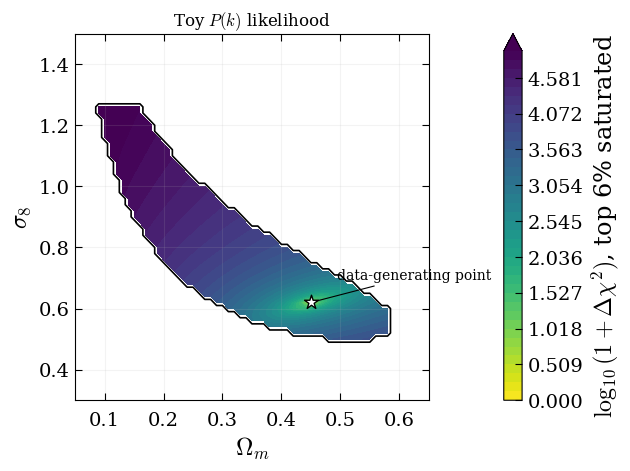

In [10]:
pk_evals = evaluate_grid(pk_model, "dq2_toy_pk", "pk", n_omega=NGRID, n_sigma8=NGRID)
plot_likelihood_plane(pk_evals, title=r"Toy $P(k)$ likelihood", data_omega_m=0.45, data_sigma8=0.62)

## `C_ell` example

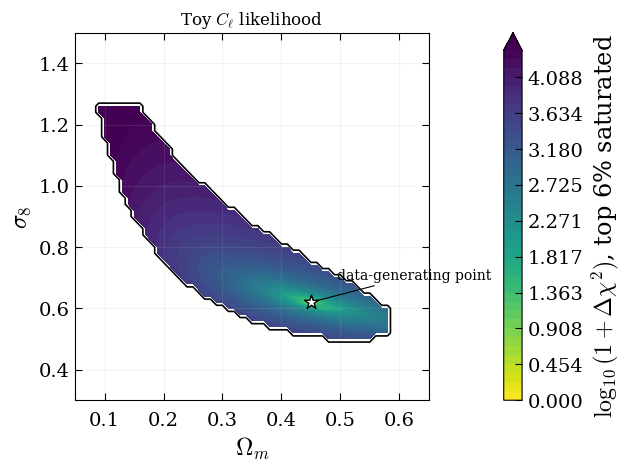

In [11]:
cl_evals = evaluate_grid(cl_model, "dq2_toy_cl", "cl", n_omega=NGRID, n_sigma8=NGRID)
plot_likelihood_plane(cl_evals, title=r"Toy $C_\ell$ likelihood", data_omega_m=0.45, data_sigma8=0.62)

## Notes for real data analyses

Keep the Dark Emulator2 call pattern, but replace the fake data vector, toy error, nuisance parameters, scale cuts, and likelihood conventions with those required by the target analysis.

For production use, pass `P(k,z)` to the downstream projection and likelihood calculation. Use a direct `C_ell` path only if the target workflow explicitly expects a precomputed angular spectrum. Emulator or theory uncertainty should be handled downstream through a validation-based theory covariance, nuisance model, or scale cut. Use a Cobaya likelihood class if the workflow depends on external data files or shared theory calculations.
